# 03 · Objetivo (iii): combinação de competências, atividades, responsabilidades e autonomia

> *"Examinar como essas competências se combinam com as atividades, as responsabilidades e as expectativas de autonomia descritas nos anúncios."* (Seção 1.3, objetivo iii)

**Perguntas**
1. Quais **perfis de cargo** (combinações das quatro dimensões) são mais comuns? (Seção 3.5)
2. Competências técnicas e socioemocionais aparecem **juntas** mais do que o acaso sugeriria? (Deming, 2017: complementaridade)
3. Há **grupos naturais** de anúncios, com combinações de competências e tecnologias parecidas?
4. As responsabilidades descritas são de **execução** ou de **julgamento**? Como isso se relaciona com autonomia? (Dutra et al.; Cunha, 2026)
5. Os anúncios descrevem **condições de aprendizagem** (mentoria, supervisão, treinamento)? (Asriyan et al., 2026) — *extensão sugerida*.
6. Exemplos reais de anúncios que combinam comunicação, resolução de problemas e IA (pendência `[P5]` do artigo).

> As partes 4 e 5 são **exploratórias**, baseadas em listas de verbos e termos. Servem para gerar hipóteses e exemplos, não para estimativas finais.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import analise_lib as L
L.estilo()
pd.set_option("display.max_colwidth", None, "display.width", 220)
df = L.carregar()
CHAVES = list(L.COMPETENCIAS); ROT = {k: v[1] for k, v in L.COMPETENCIAS.items()}; DIM = {k: v[0] for k, v in L.COMPETENCIAS.items()}
print(f"{len(df):,} anúncios")

9,964 anúncios


## 1. Perfis de cargo: combinações das quatro dimensões
Cada anúncio recebe um código com as dimensões presentes: **T** técnica, **C** cognitiva, **S** socioemocional, **M** metacognitiva.
Exemplo: `T+S` = menciona habilidade técnica e competência socioemocional, mas nenhuma cognitiva nem metacognitiva.

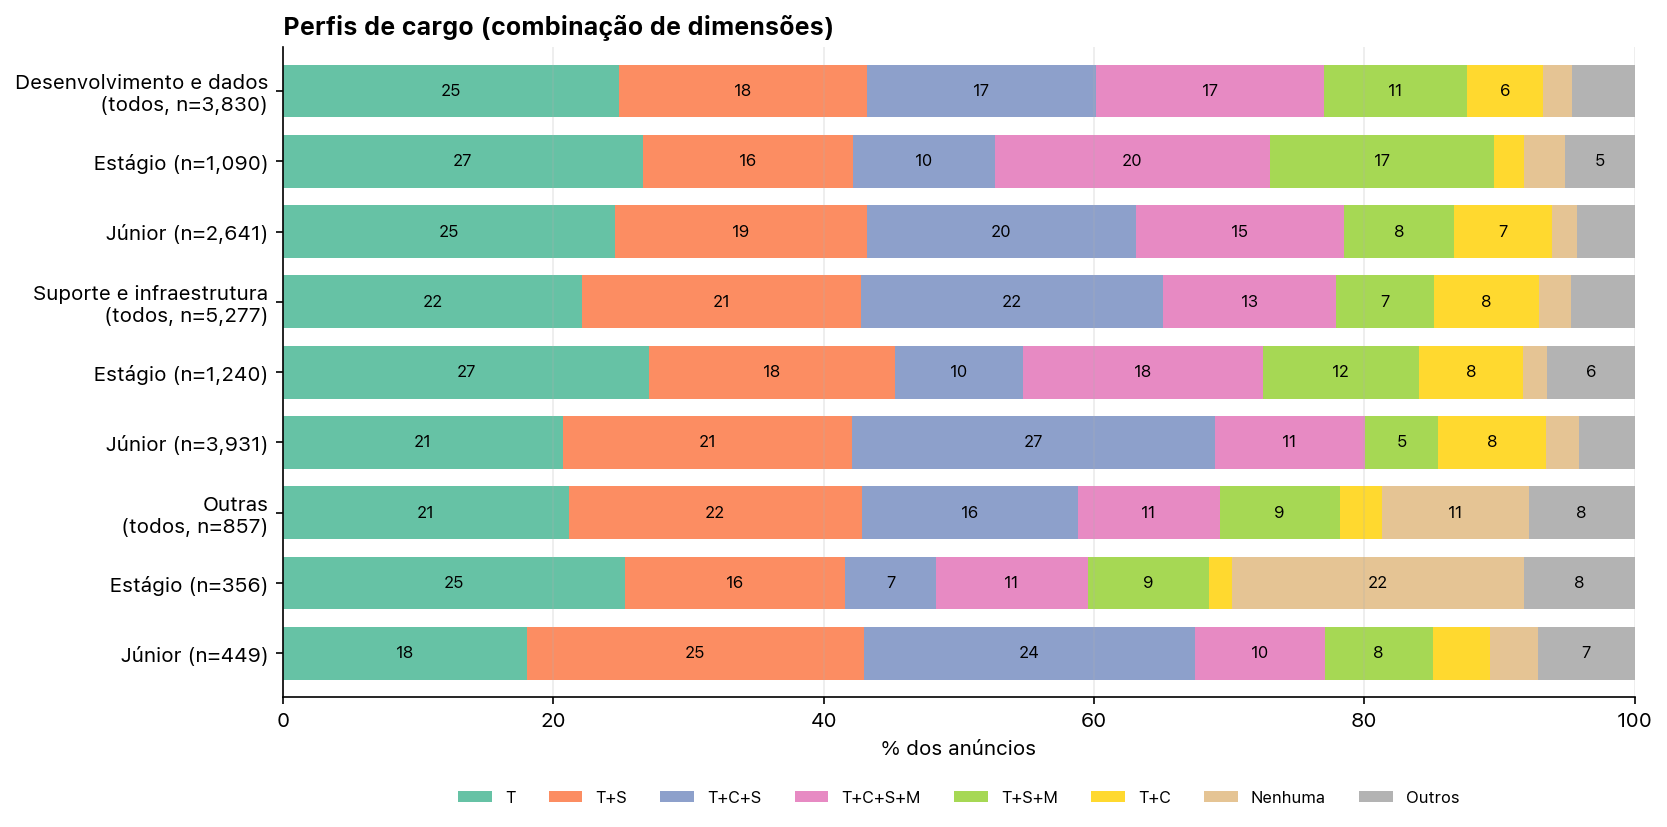

In [2]:
partes = np.array(["T", "C", "S", "M"])
mat = df[["d_tecnica", "d_cog", "d_soc", "d_met"]].to_numpy()
df["perfil"] = ["+".join(partes[r]) if r.any() else "Nenhuma" for r in mat]
df["n_dim"] = mat.sum(axis=1)
ordem_perf = df["perfil"].value_counts().index.tolist()
top = ordem_perf[:7]
df["perfil_top"] = df["perfil"].where(df["perfil"].isin(top), "Outros")
cat = top + ["Outros"]
cores = sns.color_palette("Set2", len(cat)).as_hex()

linhas = []
for g in L.ORDEM_GRUPOS:
    linhas.append((f"{g}\n(todos, n={(df.grupo == g).sum():,})", df[df.grupo == g]))
    for nv in L.NIVEIS_PRINCIPAIS:
        s = df[(df.grupo == g) & (df.nivel == nv)]
        linhas.append((f"   {nv} (n={len(s):,})", s))
P = pd.DataFrame({r: s["perfil_top"].value_counts(normalize=True).reindex(cat, fill_value=0) * 100 for r, s in linhas}).T
fig, ax = plt.subplots(figsize=(11, 5.4))
P.iloc[::-1].plot(kind="barh", stacked=True, ax=ax, color=cores, width=.75)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}" if v >= 5 else "" for v in c.datavalues], label_type="center", fontsize=8)
ax.set_xlabel("% dos anúncios"); ax.set_title("Perfis de cargo (combinação de dimensões)"); ax.grid(axis="y", visible=False); ax.set_xlim(0, 100)
ax.legend(ncol=8, loc="upper center", bbox_to_anchor=(.5, -.12), fontsize=8)
L.salvar(fig, "03_perfis"); plt.show()

In [3]:
full = pd.crosstab(df["perfil"], df["grupo"], normalize="columns").reindex(columns=L.ORDEM_GRUPOS).mul(100).round(1).loc[ordem_perf]
full["n total"] = df["perfil"].value_counts().reindex(full.index)
display(full.style.background_gradient(cmap="Blues", subset=L.ORDEM_GRUPOS).format("{:.1f}", subset=L.ORDEM_GRUPOS).set_caption("Perfis (% dentro de cada grupo)"))
full.to_csv(L.BASE / "tabela_03_perfis.csv")

grupo,Desenvolvimento e dados,Suporte e infraestrutura,Outras,n total
perfil,,,,
T,24.8,22.1,21.1,2298
T+S,18.4,20.7,21.7,1982
T+C+S,16.9,22.4,16.0,1966
T+C+S+M,16.8,12.8,10.5,1407
T+S+M,10.6,7.3,8.9,865
T+C,5.6,7.8,3.2,654
Nenhuma,2.1,2.3,10.9,298
T+M,2.3,0.9,1.1,144
S,0.4,1.5,2.2,117


## 2. Complementaridade entre competência técnica e socioemocional (Deming, 2017)
Se técnica e socioemocional fossem independentes, `P(S | T)` seria igual a `P(S | sem T)`. A razão entre elas mede a associação.
O resultado depende do tamanho do texto (anúncios longos citam mais de tudo), então a tabela repete o cálculo **dentro de cada quartil de tamanho**.

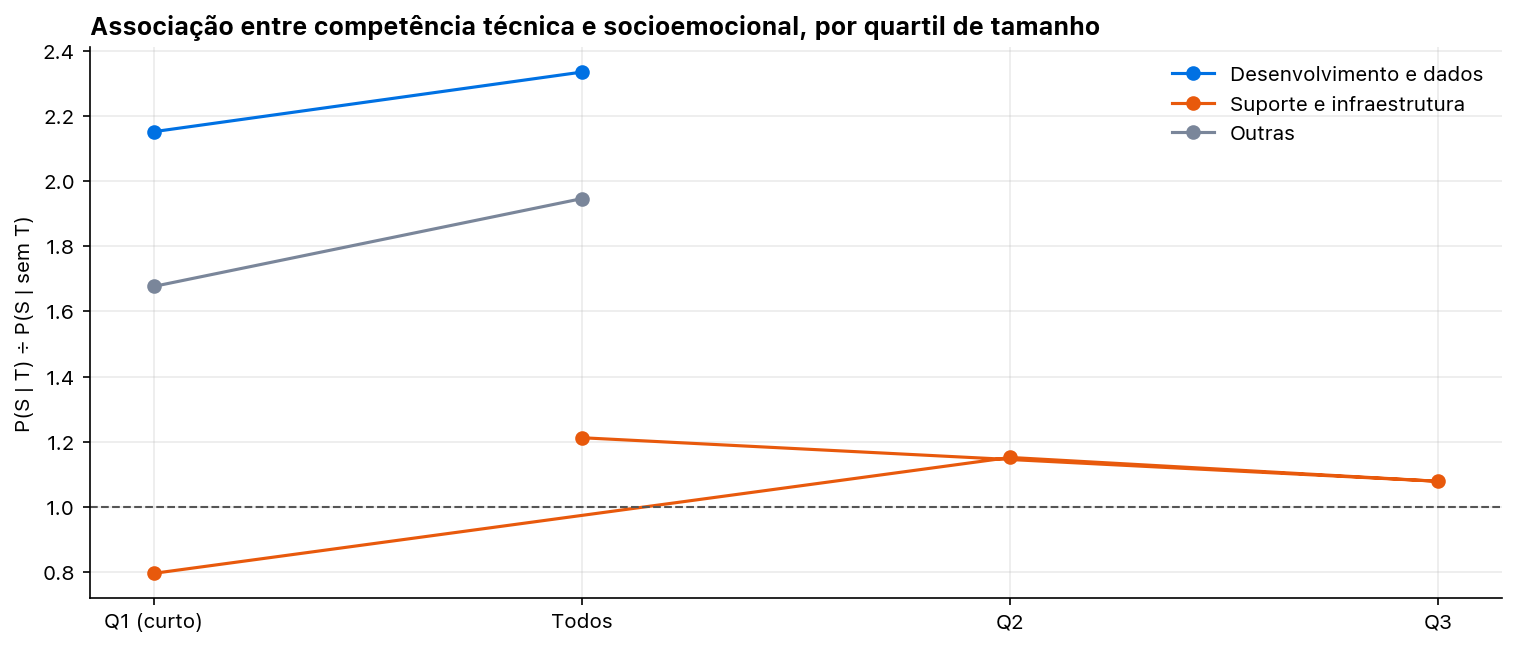

grupo,quartil,P(S|T),P(S|sem T),n_T,n_semT,razão
Desenvolvimento e dados,Q1 (curto),35.040000,16.280000,565,86,2.150000
Desenvolvimento e dados,Todos,64.780000,27.730000,3711,119,2.340000
Suporte e infraestrutura,Q1 (curto),38.320000,48.210000,1391,195,0.790000
Suporte e infraestrutura,Q2,67.610000,58.730000,1374,63,1.150000
Suporte e infraestrutura,Q3,81.660000,75.760000,1194,33,1.080000
Suporte e infraestrutura,Todos,66.930000,55.230000,4971,306,1.210000
Outras,Q1 (curto),35.710000,21.300000,154,108,1.680000
Outras,Todos,68.870000,35.370000,710,147,1.950000


In [4]:
linhas = []
for g in L.ORDEM_GRUPOS:
    for q in ["Q1 (curto)", "Q2", "Q3", "Q4 (longo)", "Todos"]:
        s = df[(df.grupo == g) & ((df.quartil_tam == q) if q != "Todos" else True)]
        a, b = s[s.d_tecnica], s[~s.d_tecnica]
        if len(a) >= 30 and len(b) >= 30:
            linhas.append({"grupo": g, "quartil": q, "P(S|T)": 100 * a.d_soc.mean(), "P(S|sem T)": 100 * b.d_soc.mean(), "n_T": len(a), "n_semT": len(b)})
comp = pd.DataFrame(linhas); comp["razão"] = comp["P(S|T)"] / comp["P(S|sem T)"]
fig, ax = plt.subplots(figsize=(10, 4.2))
for g in L.ORDEM_GRUPOS:
    s = comp[comp.grupo == g]
    ax.plot(s["quartil"], s["razão"], marker="o", color=L.PALETA[g], label=g)
ax.axhline(1, color="#555", ls="--", lw=1); ax.set_ylabel("P(S | T) ÷ P(S | sem T)"); ax.set_title("Associação entre competência técnica e socioemocional, por quartil de tamanho")
ax.legend(); L.salvar(fig, "03_complementaridade"); plt.show()
comp.to_csv(L.BASE / "tabela_03_complementaridade.csv", index=False)
display(comp.round(2).style.hide(axis="index").set_caption("Razão > 1: socioemocional é mais comum quando há técnica"))

## 3. Quais competências andam com quais tecnologias? (lift, por grupo)

**Lift** = `P(A e B) ÷ (P(A) × P(B))`. Valor 1 = independência; > 1 = aparecem juntas mais que o esperado.
A taxonomia do projeto agrupa as tecnologias (linguagens, frameworks, bancos, nuvem/DevOps...). Células com menos de 30 coocorrências ficam em branco.

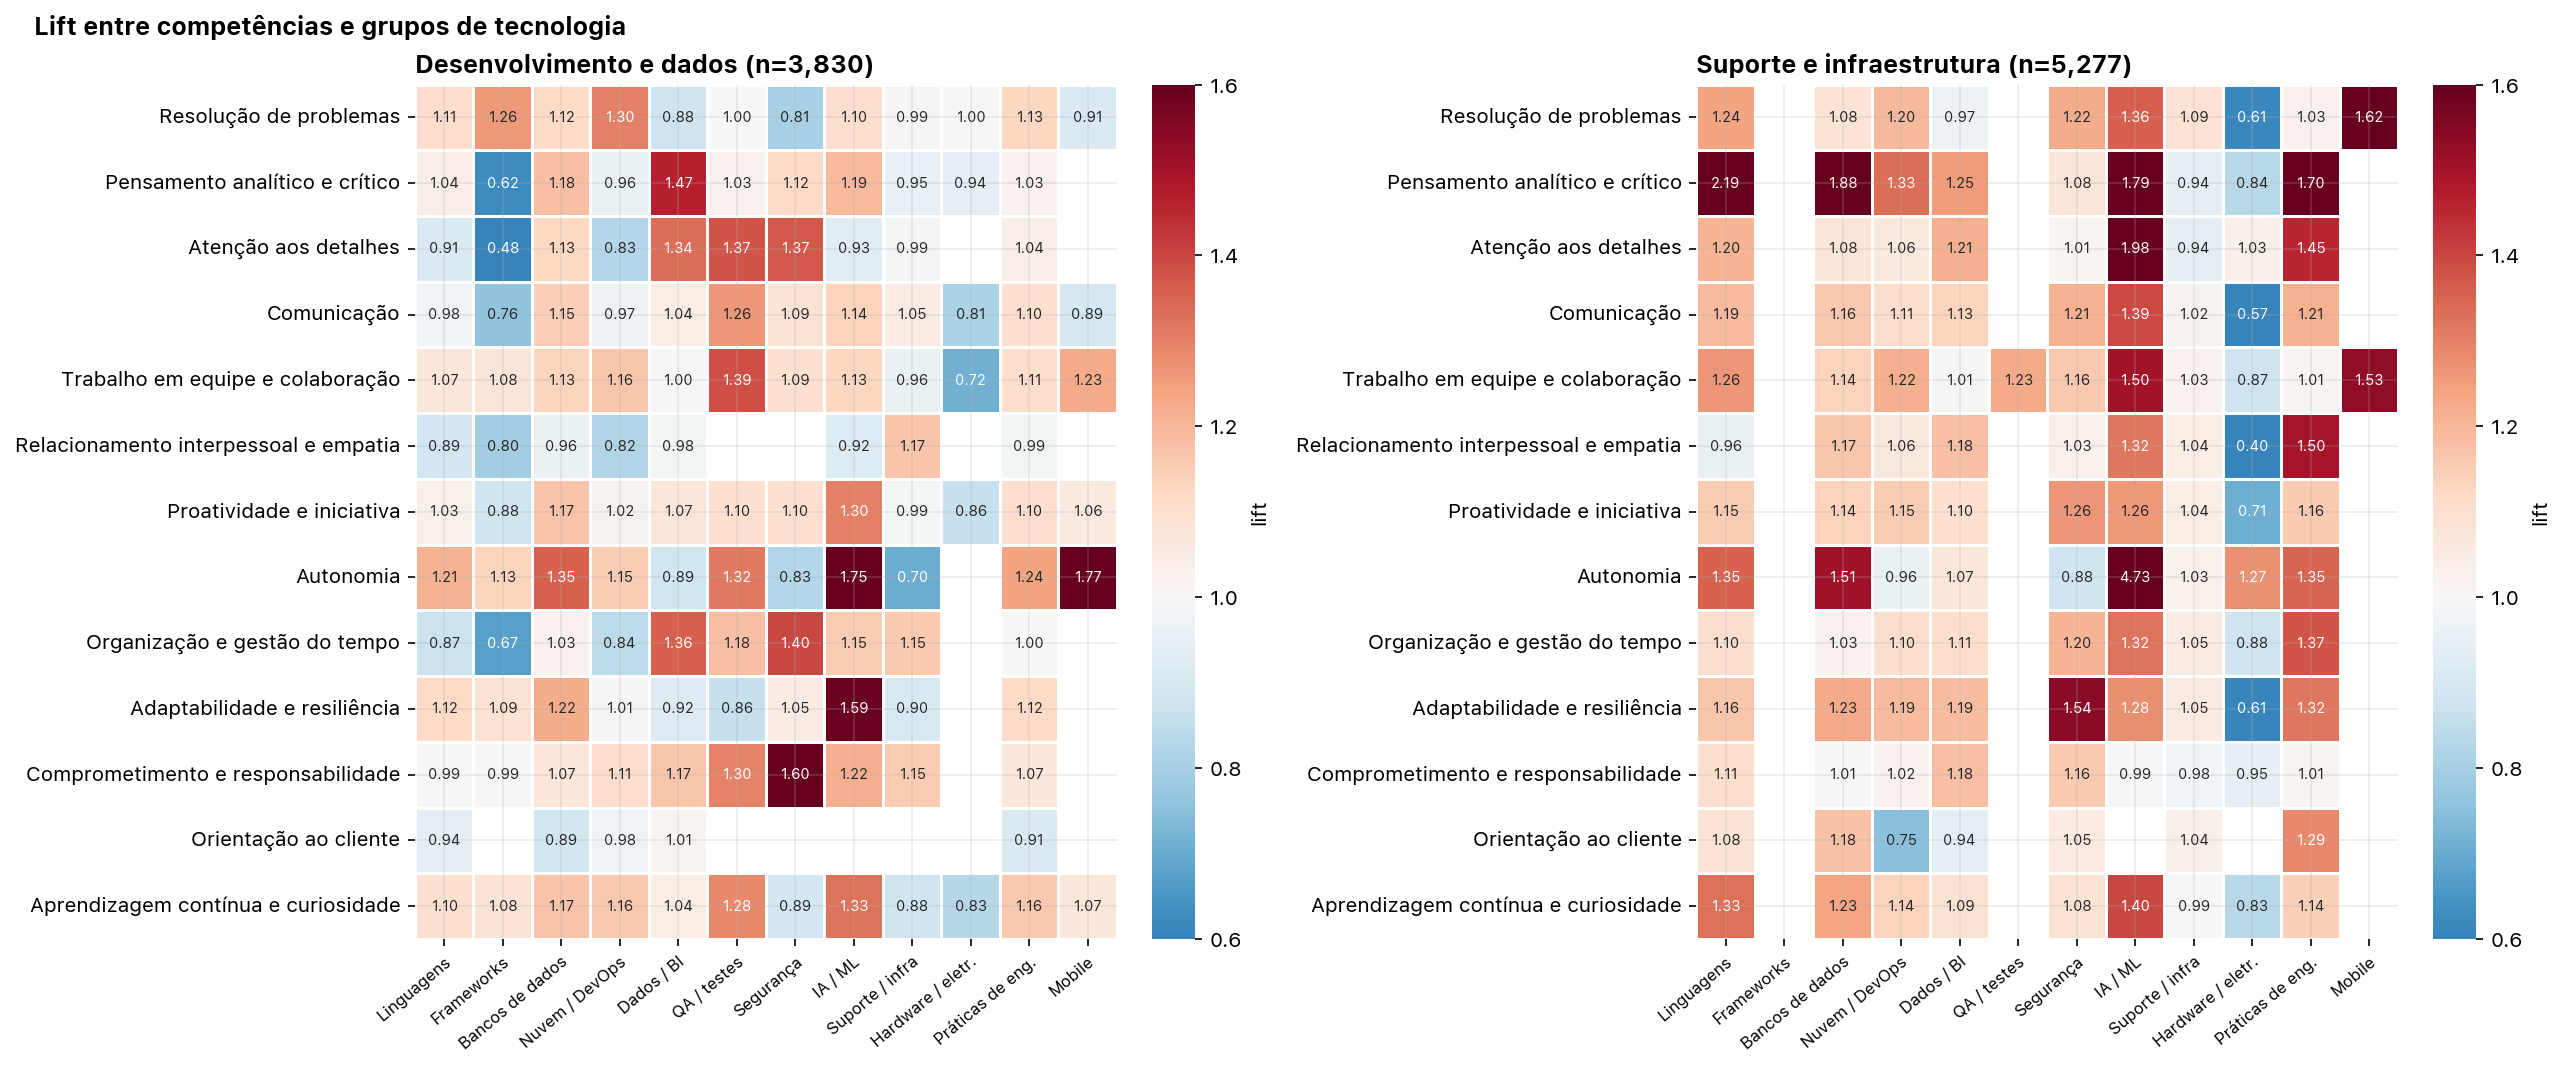

In [5]:
GT = {"linguagens": "Linguagens", "frameworks": "Frameworks", "bancos": "Bancos de dados", "cloud_devops": "Nuvem / DevOps",
      "dados": "Dados / BI", "qa_testes": "QA / testes", "seguranca": "Segurança", "inteligencia_artificial": "IA / ML",
      "suporte_infra": "Suporte / infra", "hardware_eletronica": "Hardware / eletr.", "engenharia_praticas": "Práticas de eng.", "mobile": "Mobile"}
for g_, nome in GT.items():
    df[f"gt_{g_}"] = df["sk_tec"].apply(lambda l, g_=g_: any(L.SKILL_GRUPO.get(s) == g_ for s in l))

def lift_mat(sub, min_joint=30, min_b=50):
    rows = {}
    for k in CHAVES:
        a = sub[f"c_{k}"]; pa = a.mean(); row = {}
        for g_, nome in GT.items():
            b = sub[f"gt_{g_}"]; pb = b.mean(); j = (a & b).sum()
            row[nome] = (j / len(sub)) / (pa * pb) if (j >= min_joint and b.sum() >= min_b and pa > 0) else np.nan
        rows[ROT[k]] = row
    return pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, g in zip(axes, [L.G_DEV, L.G_SUP]):
    m = lift_mat(df[df.grupo == g])
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=.6, vmax=1.6, ax=ax, linewidths=.5, cbar_kws={"label": "lift"}, annot_kws={"fontsize": 7})
    ax.set_title(f"{g} (n={(df.grupo == g).sum():,})"); ax.tick_params(axis="x", labelsize=8); plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
fig.suptitle("Lift entre competências e grupos de tecnologia", x=.01, ha="left", fontweight="bold")
L.salvar(fig, "03_lift_competencias_tecnologias"); plt.show()

## 4. Grupos naturais de anúncios (agrupamento exploratório)

K-means sobre 25 variáveis binárias (13 competências + 12 grupos tecnológicos). O número de grupos é escolhido entre 4 e 7 pela
maior silhueta, numa amostra de 3.000 anúncios. **Em dados binários a silhueta costuma ser baixa**; os grupos descrevem tendências, não categorias nítidas.

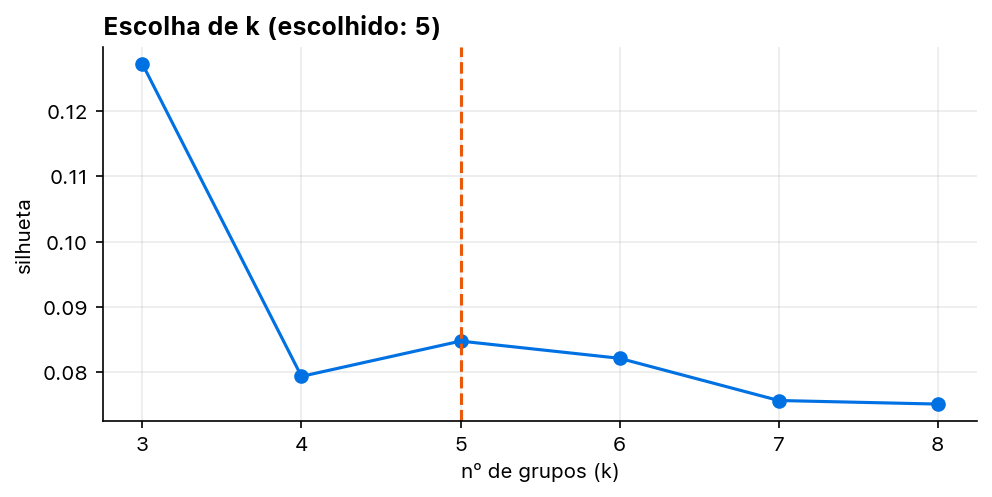

{3: 0.127, 4: 0.079, 5: 0.085, 6: 0.082, 7: 0.076, 8: 0.075}


In [6]:
feat = [f"c_{k}" for k in CHAVES] + [f"gt_{g_}" for g_ in GT]
X = df[feat].astype(float).to_numpy()
ok = X.sum(axis=1) > 0
Xo = X[ok]
rng = np.random.default_rng(5)
amostra = rng.choice(len(Xo), size=min(3000, len(Xo)), replace=False)
sil = {}
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=5, random_state=1).fit(Xo)
    sil[k] = silhouette_score(Xo[amostra], km.labels_[amostra])
kbest = max((k for k in sil if 4 <= k <= 7), key=sil.get)
km = KMeans(n_clusters=kbest, n_init=20, random_state=1).fit(Xo)
df["cluster"] = -1; df.loc[ok, "cluster"] = km.labels_
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(list(sil), list(sil.values()), marker="o", color="#0071E3"); ax.axvline(kbest, color="#E8590C", ls="--")
ax.set_xlabel("nº de grupos (k)"); ax.set_ylabel("silhueta"); ax.set_title(f"Escolha de k (escolhido: {kbest})"); plt.show()
print({k: round(float(v), 3) for k, v in sil.items()})

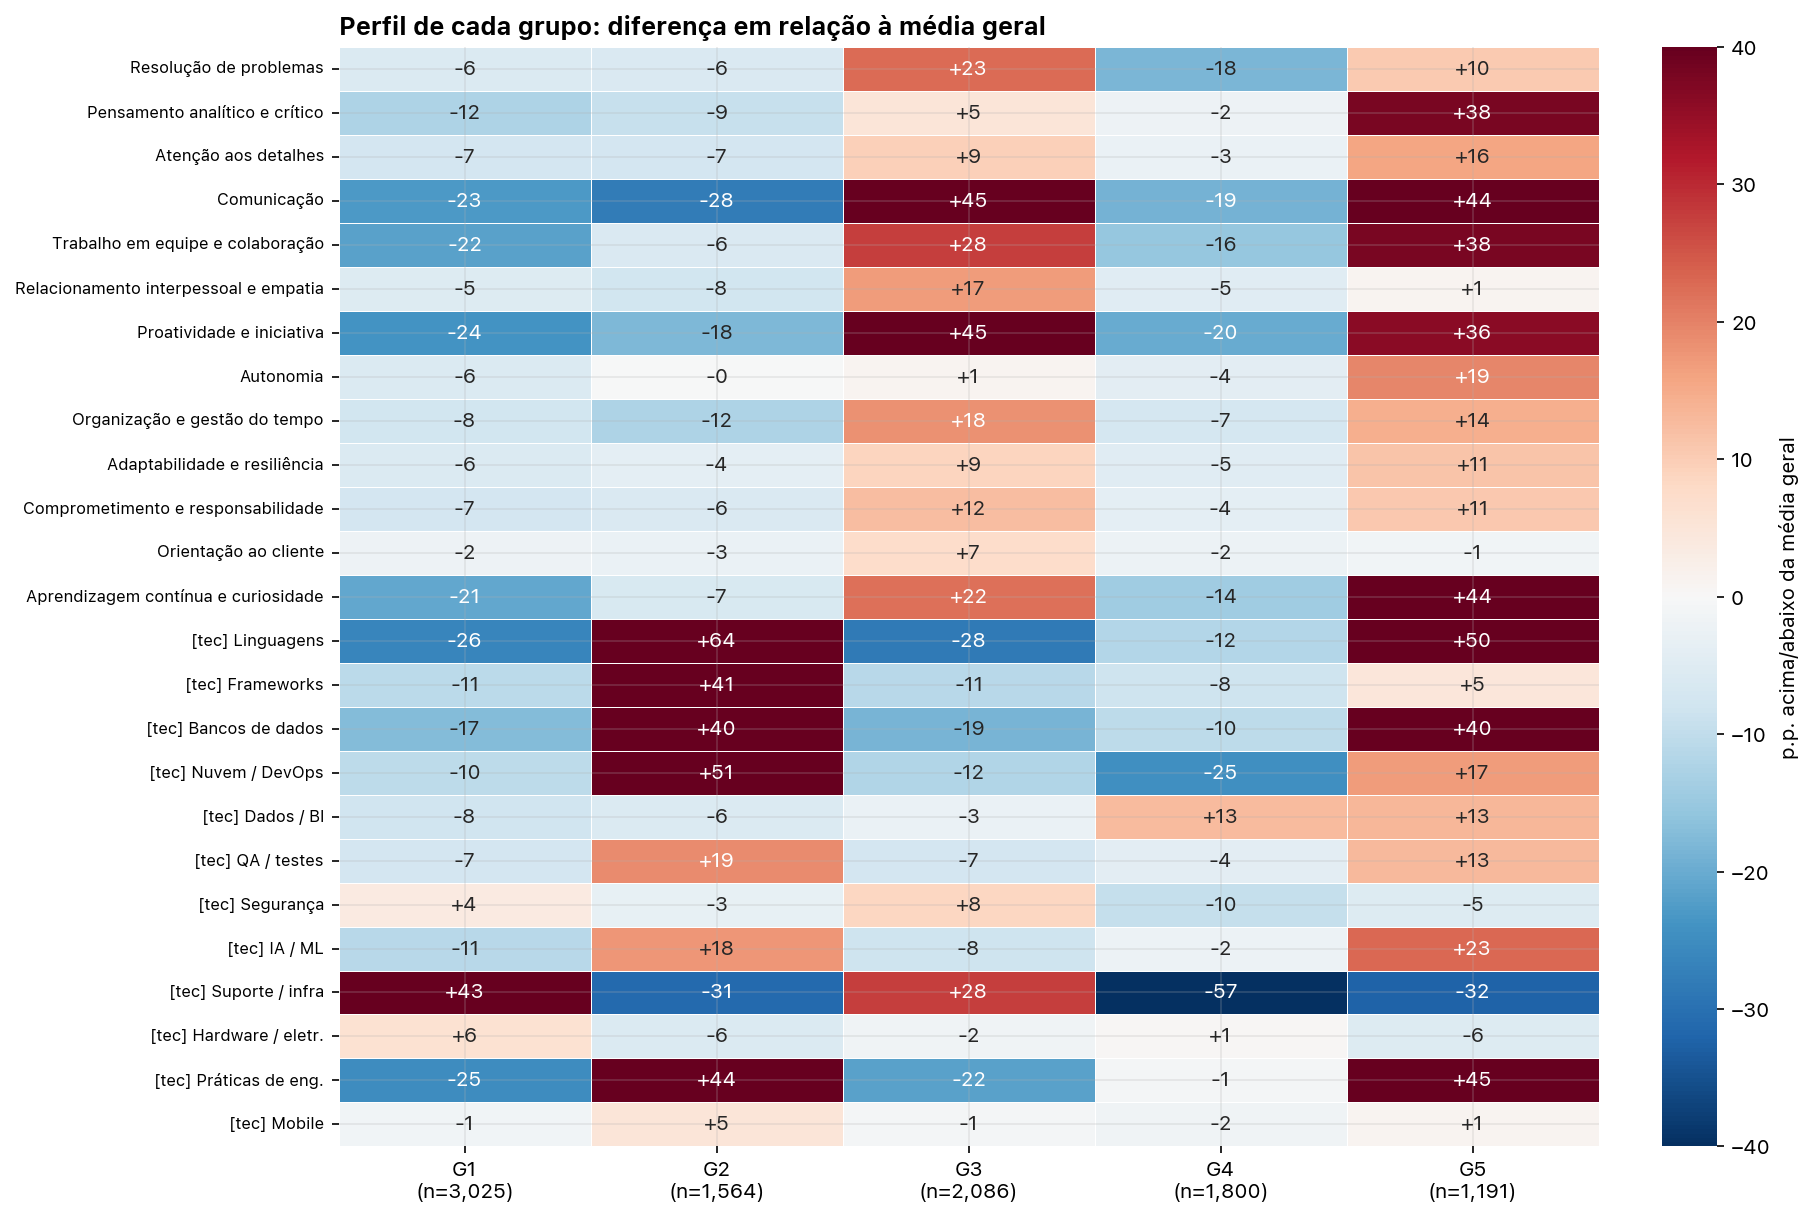

Grupo,Características mais marcantes,n
G1,"Suporte / infra, Hardware / eletr., Segurança",3025
G2,"Linguagens, Nuvem / DevOps, Práticas de eng.",1564
G3,"Comunicação, Proatividade e iniciativa, Suporte / infra",2086
G4,"Dados / BI, Hardware / eletr., Práticas de eng.",1800
G5,"Linguagens, Práticas de eng., Comunicação",1191


In [7]:
nomes_feat = {f"c_{k}": ROT[k] for k in CHAVES} | {f"gt_{g_}": f"[tec] {n}" for g_, n in GT.items()}
perfil_cl = df[df.cluster >= 0].groupby("cluster")[feat].mean() * 100
base = df.loc[df.cluster >= 0, feat].mean() * 100
dif = (perfil_cl - base).T.rename(index=nomes_feat)
tam = df[df.cluster >= 0]["cluster"].value_counts().sort_index()
# nome automático: 3 características com maior diferença positiva
def nome_cl(c):
    top3 = dif[c].sort_values(ascending=False).head(3).index
    return f"G{c + 1} · " + ", ".join(t.replace("[tec] ", "") for t in top3)
rot_cl = {c: nome_cl(c) for c in dif.columns}
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(dif.rename(columns=lambda c: f"G{c + 1}\n(n={tam[c]:,})"), annot=True, fmt="+.0f", cmap="RdBu_r", center=0, vmin=-40, vmax=40, linewidths=.4, ax=ax, cbar_kws={"label": "p.p. acima/abaixo da média geral"})
ax.set_title("Perfil de cada grupo: diferença em relação à média geral"); ax.tick_params(axis="y", labelsize=8); ax.set_xlabel(""); ax.set_ylabel("")
L.salvar(fig, "03_clusters_perfil"); plt.show()
display(pd.DataFrame({"Grupo": [f"G{c + 1}" for c in dif.columns], "Características mais marcantes": [rot_cl[c].split("· ")[1] for c in dif.columns], "n": [tam[c] for c in dif.columns]}).style.hide(axis="index"))

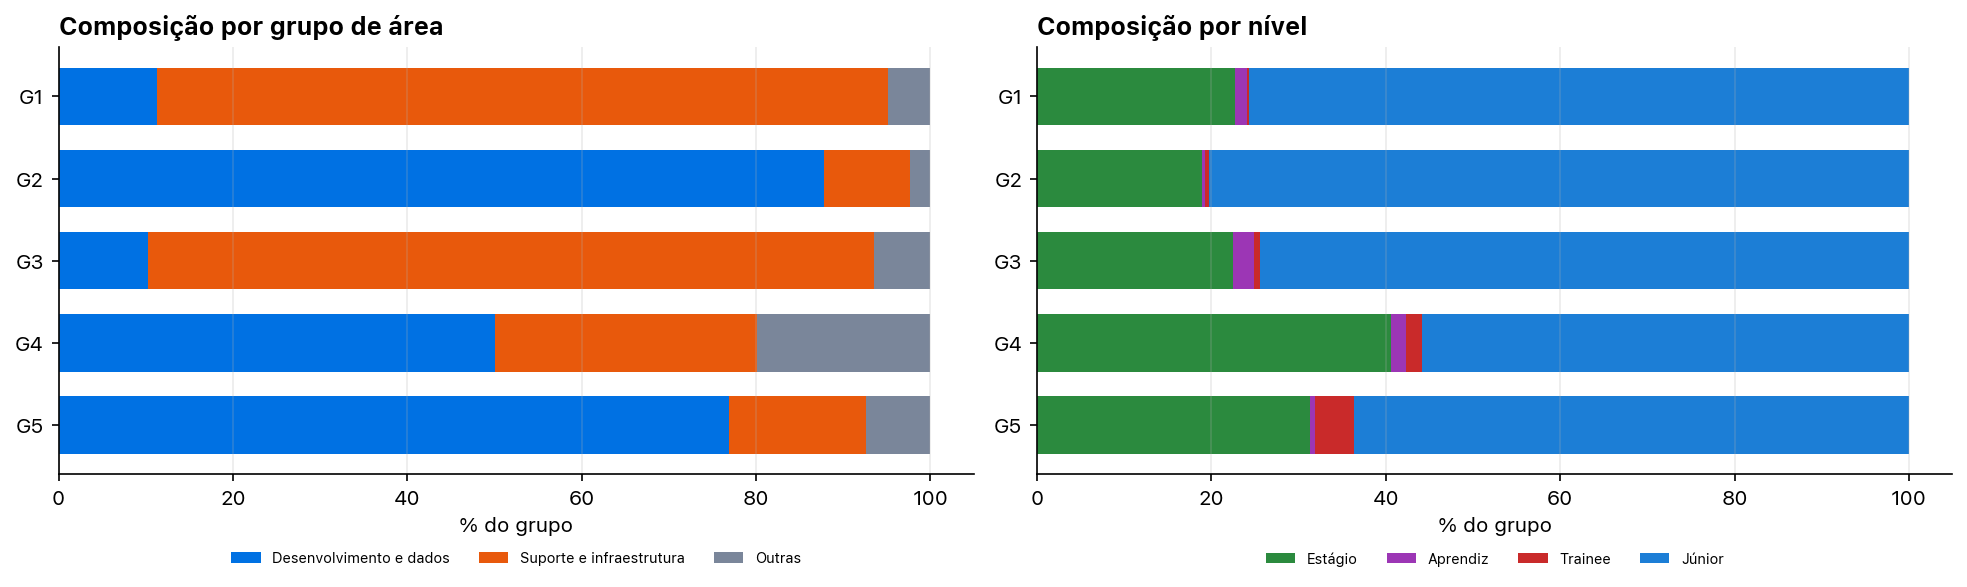

In [8]:
comp_cl = pd.crosstab(df[df.cluster >= 0]["cluster"], df[df.cluster >= 0]["grupo"], normalize="index").reindex(columns=L.ORDEM_GRUPOS).mul(100)
comp_cl.index = [f"G{c + 1}" for c in comp_cl.index]
niv_cl = pd.crosstab(df[df.cluster >= 0]["cluster"], df[df.cluster >= 0]["nivel"], normalize="index").reindex(columns=L.ORDEM_NIVEIS).mul(100)
niv_cl.index = comp_cl.index
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
comp_cl.plot(kind="barh", stacked=True, ax=axes[0], color=[L.PALETA[g] for g in comp_cl.columns], width=.7); axes[0].set_title("Composição por grupo de área"); axes[0].invert_yaxis(); axes[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.15), ncol=3)
niv_cl.plot(kind="barh", stacked=True, ax=axes[1], color=[L.PALETA_NIVEL[n] for n in niv_cl.columns], width=.7); axes[1].set_title("Composição por nível"); axes[1].invert_yaxis(); axes[1].legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.15), ncol=4)
for ax in axes: ax.set_xlabel("% do grupo"); ax.grid(axis="y", visible=False)
L.salvar(fig, "03_clusters_composicao"); plt.show()

## 5. Execução × julgamento nas responsabilidades (exploratório)

Conta verbos de **execução** (*auxiliar, apoiar, executar, atender, registrar, instalar, configurar...*) e de **julgamento**
(*analisar, propor, definir, planejar, avaliar, diagnosticar, otimizar, liderar, priorizar, validar...*) em cada anúncio.
O **índice de julgamento** é `julgamento ÷ (julgamento + execução)`, calculado só em anúncios com ao menos 3 verbos; ele corrige o efeito do tamanho do texto.
Conexão teórica: distinção de Dutra et al. entre procedimentos conhecidos e situações menos estruturadas; Cunha (2026) sobre a IA substituir primeiro tarefas estruturadas.
**Limitação:** o texto inteiro é analisado, não apenas a seção de responsabilidades, e "analisar/definir" aparecem também em descrições genéricas.

Anúncios com ≥ 3 verbos: 9,008 (90%)


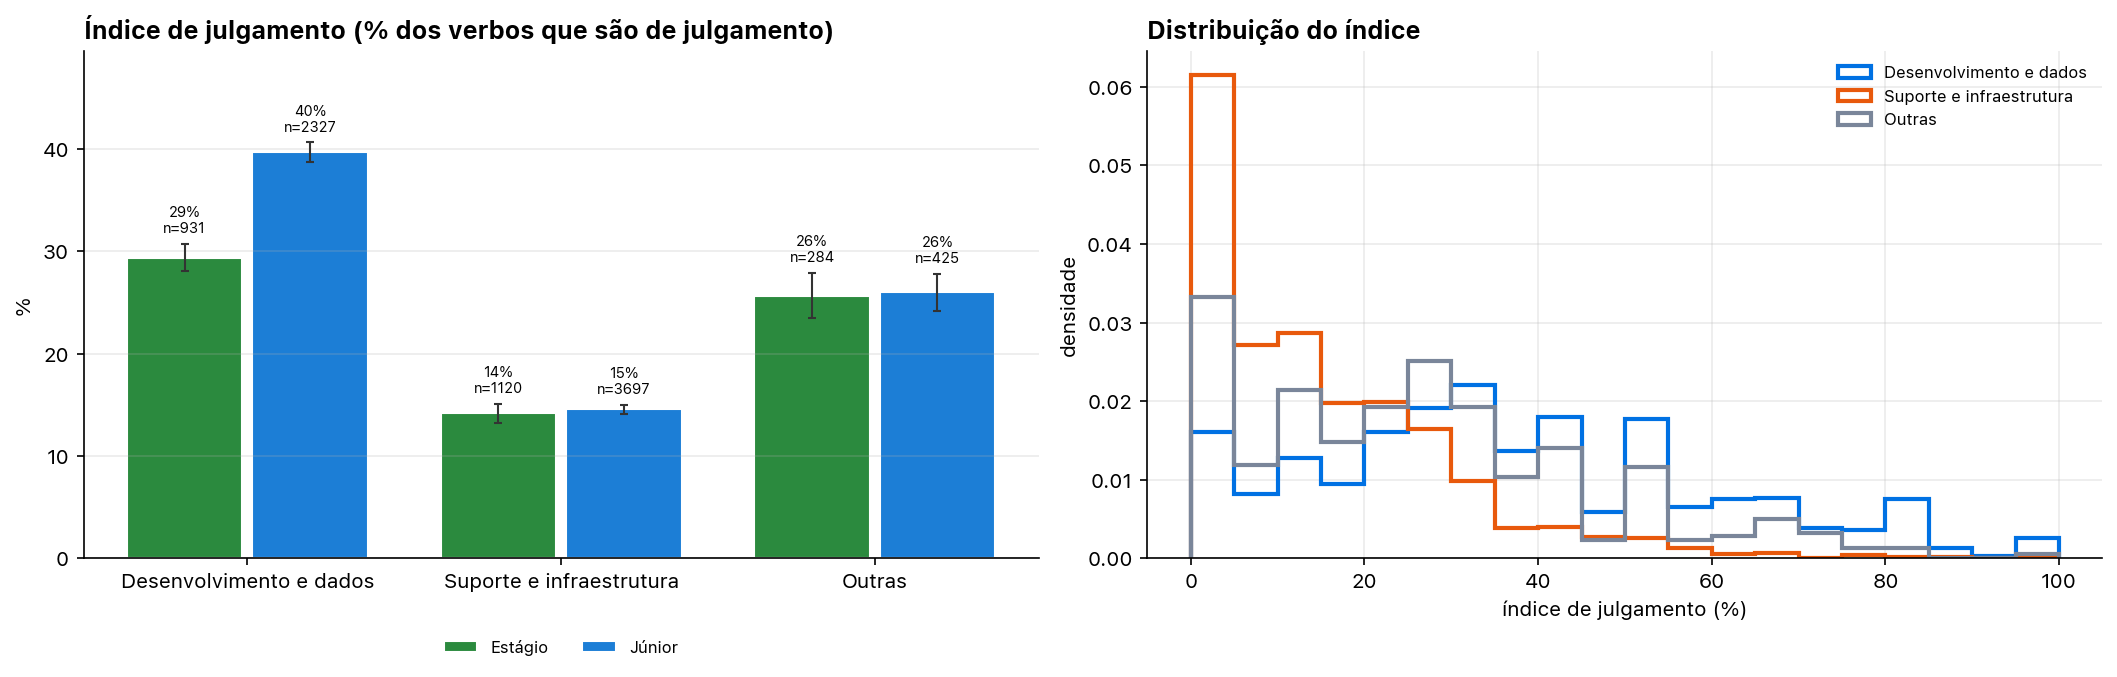

In [9]:
df["n_verbos"] = df["v_exec"] + df["v_julg"]
v = df[df["n_verbos"] >= 3].copy()
v["ind_julg"] = v["v_julg"] / v["n_verbos"]
print(f"Anúncios com ≥ 3 verbos: {len(v):,} ({len(v) / len(df):.0%})")
res = []
for g in L.ORDEM_GRUPOS:
    for nv in L.NIVEIS_PRINCIPAIS:
        s = v[(v.grupo == g) & (v.nivel == nv)]
        m = s["ind_julg"].mean() * 100; se = s["ind_julg"].std() / np.sqrt(len(s)) * 100
        res.append({"grupo": g, "nivel": nv, "pct": m, "ic_lo": m - 1.96 * se, "ic_hi": m + 1.96 * se, "n": len(s)})
vt = pd.DataFrame(res)
vt.to_csv(L.BASE / "tabela_03_julgamento.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
L.barras_prop(axes[0], vt, "grupo", "nivel", L.ORDEM_GRUPOS, L.NIVEIS_PRINCIPAIS, L.PALETA_NIVEL)
axes[0].set_title("Índice de julgamento (% dos verbos que são de julgamento)"); axes[0].set_ylabel("%")
ax = axes[1]
for g in L.ORDEM_GRUPOS:
    s = v[v.grupo == g]
    ax.hist(s["ind_julg"] * 100, bins=20, histtype="step", lw=2, color=L.PALETA[g], label=g, density=True)
ax.set_xlabel("índice de julgamento (%)"); ax.set_ylabel("densidade"); ax.set_title("Distribuição do índice"); ax.legend(fontsize=8)
L.salvar(fig, "03_execucao_julgamento"); plt.show()

### Autonomia e proatividade × julgamento
Anúncios que mencionam **autonomia** descrevem também mais atividades de julgamento? (Cada ponto é a média do índice por categoria.)

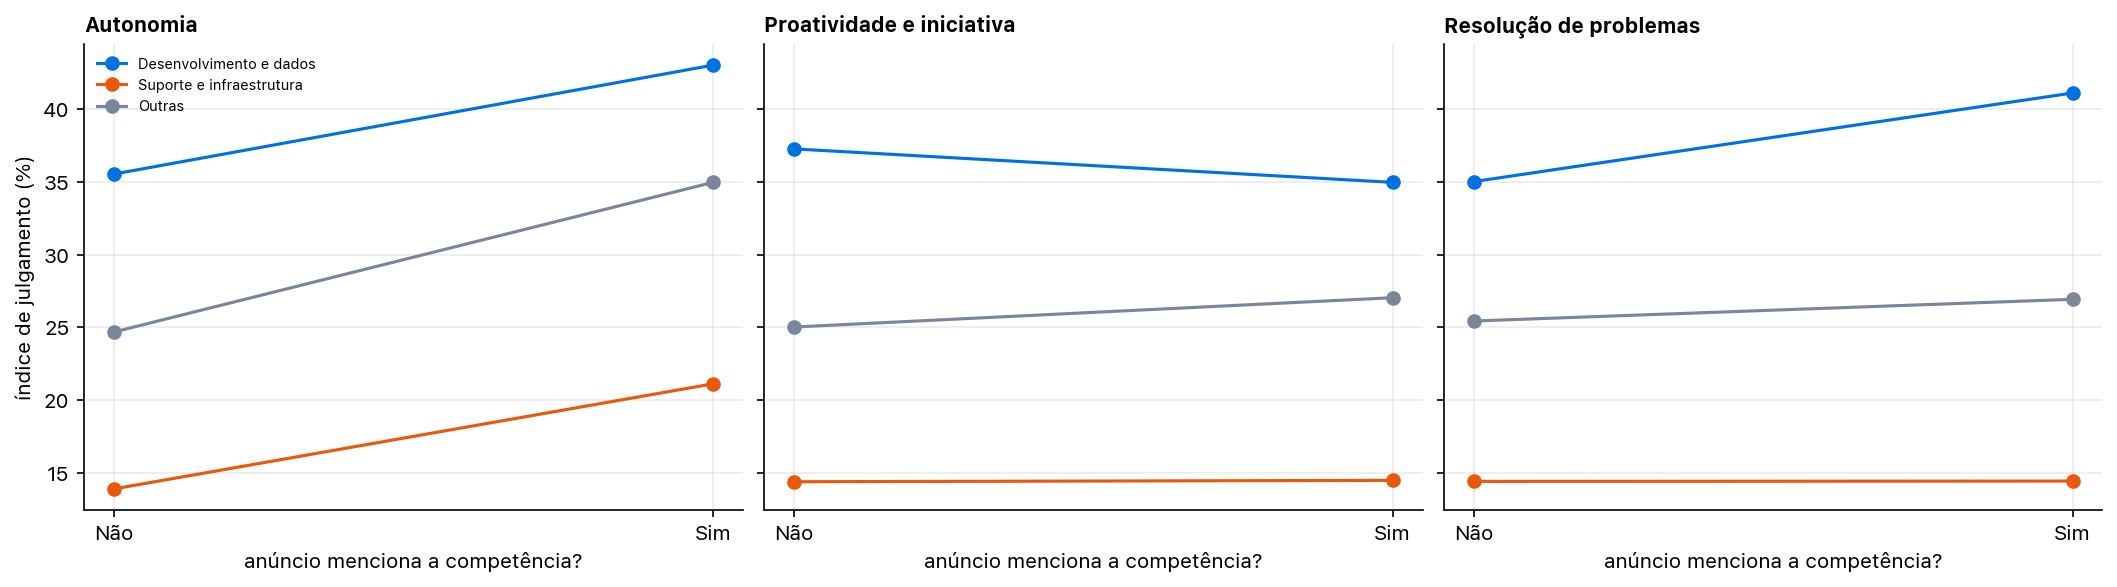

In [10]:
rows = []
for g in L.ORDEM_GRUPOS:
    for nome, col in (("Autonomia", "c_autonomia"), ("Proatividade e iniciativa", "c_proatividade"), ("Resolução de problemas", "c_resolucao_problemas")):
        s = v[v.grupo == g]
        for flag in (False, True):
            ss = s[s[col] == flag]
            rows.append({"grupo": g, "competencia": nome, "menciona": "Sim" if flag else "Não", "ind": ss["ind_julg"].mean() * 100, "n": len(ss)})
at = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, nome in zip(axes, at["competencia"].unique()):
    s = at[at.competencia == nome]
    for g in L.ORDEM_GRUPOS:
        ss = s[s.grupo == g].set_index("menciona").loc[["Não", "Sim"]]
        ax.plot(ss.index, ss["ind"], marker="o", color=L.PALETA[g], label=g)
    ax.set_title(nome, fontsize=10); ax.set_xlabel("anúncio menciona a competência?")
axes[0].set_ylabel("índice de julgamento (%)"); axes[0].legend(fontsize=7)
L.salvar(fig, "03_autonomia_julgamento"); plt.show()

## 6. Condições de aprendizagem declaradas (extensão sugerida)

Dialoga com Asriyan et al. (2026): se as tarefas de entrada formam o trabalhador, os anúncios descrevem **apoio à aprendizagem**?
Termos: *mentoria, supervisão, acompanhamento, programa de desenvolvimento, treinamento, capacitação, onboarding*.
Seções de benefícios já foram removidas pelo recorte (muitos "treinamentos" estariam ali), então os valores abaixo são um **piso**.

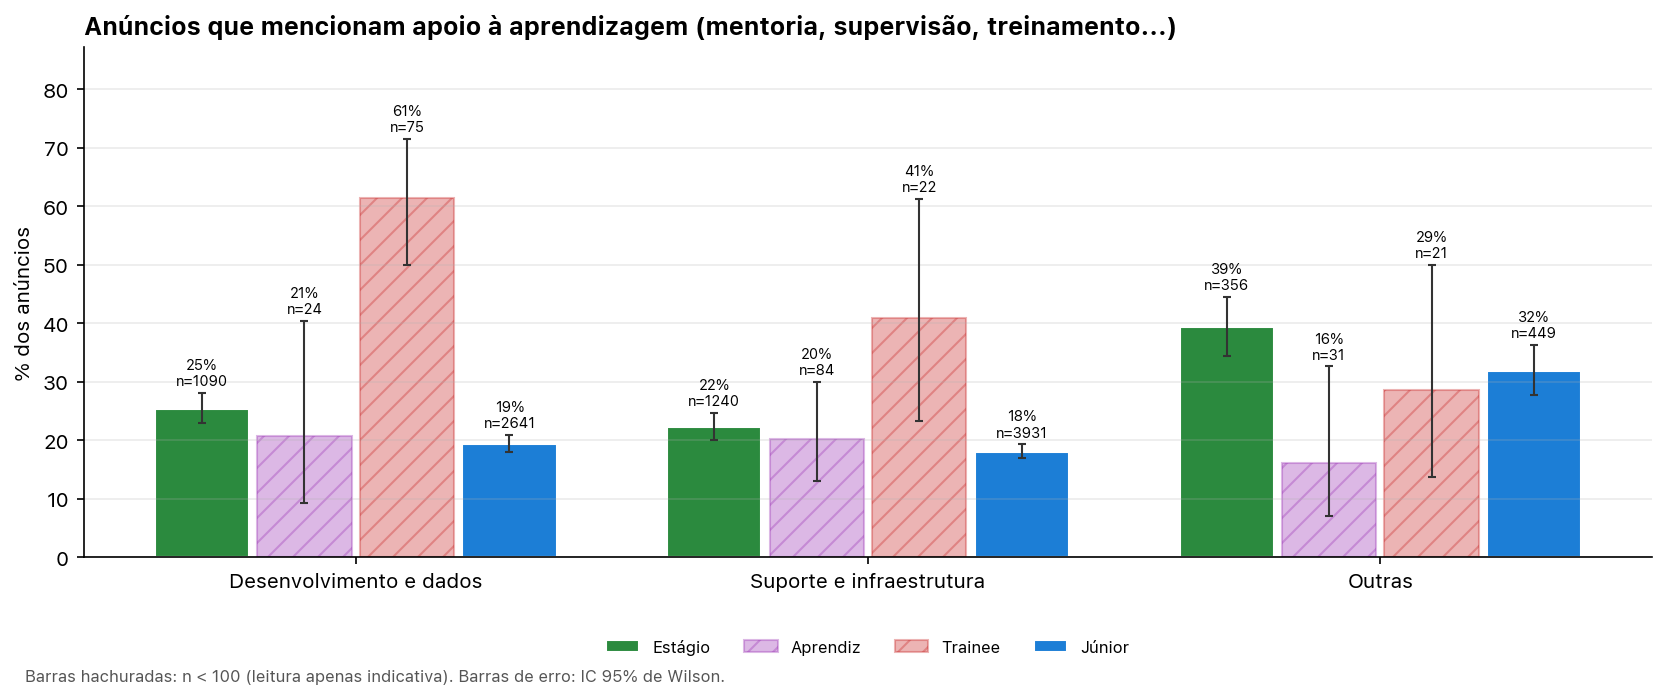

Área,Nível,Trecho
Suporte Técnico,Júnior,…; Seguir e atualizar as etapas do funil do CRM para atendimento de suporte técnico e agendamento de treinamento aos clientes; Definir com cliente requisitos de instalação; Realizar orçamentos de montagem; Agenda…
Infraestrutura / Redes,Júnior,…dos maiores programas de voluntariado corporativo para você transformar o mundo;• Usufruir do nosso Programa de Desenvolvimento Educacional que oferece parcerias em instituições de ensino com desconto; certificações e cursos on…
Engenharia de Software,Estágio,…stes e depuração de software para garantir a qualidade e funcionalidade; Fornecer suporte técnico e treinamento para usuários finais; Manter-se atualizado com as últimas tendências e atualizações do ecossistema…
Fullstack,Júnior,…s que formam a essência da .add. Aqui na .add você vai encontrar: Ambiente colaborativo Circuito de treinamentos Hibrído 1 vez na semana - Centro Rj Programa de Educação Continuada Flash Requisitos: Experiência i…
Fullstack,Júnior,"…(anywhere office, híbrido ou presencial) e investimos em desenvolvimento contínuo com BRQ Academy, mentoria, incentivo a certificações e programas de idiomas, entre outras frentes. Diversidade, inclusão e li…"
Sistemas / ERP,Júnior,"…orma. Realizar configurações iniciais do sistema conforme a operação do cliente. Agendar e conduzir treinamentos on-line (e presenciais, quando necessário). Esclarecer dúvidas e acompanhar a evolução do cliente d…"


In [11]:
RX_APREND = re.compile(r"mentoria|mentor\w*|sob supervisao|supervisao (de|do|da)|acompanhamento (de|do|da) (um )?(profissional|time|equipe|gestor|lider|senior)|programa de (desenvolvimento|capacitacao|formacao|estagio)|plano de (desenvolvimento|carreira)|treinamento\w*|capacitac\w+|aprender com|aprendizado (com|junto)|onboarding|trilha de (aprendizado|desenvolvimento)")
df["apoio_aprend"] = df["tf"].map(lambda t: bool(RX_APREND.search(t)))
t = L.tabela_prop(df, "apoio_aprend", ["grupo", "nivel"])
t.to_csv(L.BASE / "tabela_03_apoio_aprendizagem.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 4.4))
L.barras_prop(ax, t, "grupo", "nivel", L.ORDEM_GRUPOS, L.ORDEM_NIVEIS, L.PALETA_NIVEL)
ax.set_title("Anúncios que mencionam apoio à aprendizagem (mentoria, supervisão, treinamento...)"); L.nota_n_pequeno(fig)
L.salvar(fig, "03_apoio_aprendizagem"); plt.show()
ex = df[df.apoio_aprend].sample(6, random_state=4)
display(pd.DataFrame([{"Área": r["area"], "Nível": r["nivel"], "Trecho": L.trecho(r["texto"], m.start(), m.end(), 100)}
                      for _, r in ex.iterrows() for m in [RX_APREND.search(r["tf"])]]).style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "11px"}))

## 7. Exemplos de anúncios para a Seção 2.3 (`[P5]`)

A orientadora pediu "2 a 3 exemplos de trechos de anúncios da amostra que ilustrem essa combinação — comunicação, resolução de problemas e menção a ferramentas de IA".
A tabela abaixo seleciona, no grupo **Desenvolvimento e dados** (sem a área IA), anúncios que reúnem as três coisas.
**Escolha final a cargo das autoras**: abaixo vão candidatos aleatórios e curtos.

In [12]:
dd = df[(df.grupo == L.G_DEV) & (df.area != "Inteligência Artificial")]
tri = dd[dd.c_comunicacao & dd.c_resolucao_problemas & dd.genai]
print(f"Desenvolvimento e dados (sem IA): {len(dd):,} anúncios | com comunicação + resolução de problemas + IA generativa: {len(tri)} ({len(tri) / len(dd):.1%})")
print(f"  só comunicação + resolução: {(dd.c_comunicacao & dd.c_resolucao_problemas).mean():.1%} | só IA generativa: {dd.genai.mean():.1%}")
rx_com, rx_res, rx_ia = (re.compile(L.COMPETENCIAS["comunicacao"][2]), re.compile(L.COMPETENCIAS["resolucao_problemas"][2]), re.compile(L._GENAI_TERMOS.pattern))
cand = tri[(tri.n_chars_aparado < 2500)].sample(min(6, len(tri)), random_state=8)
rows = []
for _, r in cand.iterrows():
    def tr(rx):
        m = rx.search(r["tf"]); return L.trecho(r["texto"], m.start(), m.end(), 70) if m else "(termo não localizado)"
    rows.append({"Área / nível": f"{r['area']} · {r['nivel']}", "Comunicação": tr(rx_com), "Resolução de problemas": tr(rx_res), "IA generativa": tr(rx_ia)})
display(pd.DataFrame(rows).style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "11px"}))

Desenvolvimento e dados (sem IA): 3,738 anúncios | com comunicação + resolução de problemas + IA generativa: 48 (1.3%)
  só comunicação + resolução: 10.2% | só IA generativa: 11.2%


Área / nível,Comunicação,Resolução de problemas,IA generativa
Backend · Júnior,…are com foco em .net core. Capacidade de trabalhar em equipe com boas habilidades de comunicação organização e resolução de problemas Formação em ciência da computaçã…,"…trabalhar em equipe com boas habilidades de comunicação organização e resolução de problemas Formação em ciência da computação, sistemas de informação ou áreas a…","…lacionais e controle de versão como git. Diferencial: conhecimento em ferramentas de IA para programação (Ex: cursor, claude code, codex) e conhecimento basi…"
Fullstack · Júnior,"…L Server. Facilidade para aprendizado contínuo. Perfil colaborativo e boa comunicação. Organização, proatividade e capacidade de resolução de problemas. In…","…borativo e boa comunicação. Organização, proatividade e capacidade de resolução de problemas. Interesse por inovação, tecnologia e Inteligência Artificial. Será…",…r fazer parte de um time que desenvolve soluções inovadoras e utiliza IA Generativa para transformar produtos digitais? Essa oportunidade é para você! O…
Data · Júnior,…icos; 🔹 Atenção aos detalhes; 🔹 Curiosidade e aprendizado contínuo; 🔹 Boa comunicação. 💙,…o lógico e pensamento analítico; 🔹 Pensamento crítico e capacidade de resolver problemas; 🔹 Interpretação de dados e gráficos; 🔹 Atenção aos detalhes; 🔹 Curi…,"…iais: 🔹 Conhecimento em Power BI; 🔹 Conhecimento em Machine Learning, LLMs (modelos de linguagem) e OCR (extração de texto de documentos e image…"
Fullstack · Júnior,…em Espanhol. Competências comportamentais Perfil analítico e proativo Boa comunicação e relacionamento interpessoal Capacidade de resolução de problemas Or…,…proativo Boa comunicação e relacionamento interpessoal Capacidade de resolução de problemas Organização e senso de prioridade Trabalho em equipe Aprendizado con…,(termo não localizado)
Data · Júnior,"…t Skills: perfil hands-on e curioso, organização, atenção ao detalhe, boa comunicação com áreas não técnicas e senso de dono para investigar um problema at…","…dade de IA: vontade de usar inteligência artificial no dia a dia para resolver problemas, prototipar e construir soluções — descrevendo bem o problema, revis…","…ema de sistema, montar um relatório e automatizar uma rotina — usando IA como aliada para entregar mais e melhor. É a chance de aprender amplo…"
Fullstack · Júnior,"…rvised Fine-Tuning) . 👤 Perfil Buscamos uma pessoa proativa, curiosa, comunicativa, organizada e com facilidade para aprender , que goste de solucionar…","…omunicativa, organizada e com facilidade para aprender , que goste de solucionar problemas e tenha interesse em IA, automação e desenvolvimento de produtos . 📈…","…ra atuar no desenvolvimento e evolução da SONIA , nossa plataforma de Agentes de IA, além de soluções e produtos personalizados. Você trabalhará com dese…"


### Como interpretar
- **Perfis** descrevem combinações de menções; não indicam nível de complexidade nem qualidade do cargo.
- A **associação** entre técnica e socioemocional é calculada dentro de quartis de tamanho. Se a razão ficar acima de 1 em todos eles, a conclusão de complementaridade é mais sólida do que o valor bruto.
- Os **grupos do K-means** são hipóteses de tipologia, a ser confrontadas com a lista de áreas do projeto (as 18 áreas).
- O **índice de julgamento** e o **apoio à aprendizagem** são regras simples sobre texto; úteis para exemplos e hipóteses, mas devem ser validados antes de virar resultado principal.